# Birth-death diffusion sampling: interface (stand-alone)
IE 643 course project. Runs on its own: no training cells needed.

**Before running:** right panel → Accelerator **GPU T4**, Internet **On**, and **Add Input** → the dataset with
`score_ema_L.pt` (large model) and/or `score_ema.pt` (small model), `noisy_clf.pt`, `eval_clf.pt`.
Then *Run All*. Cell 2 prints a public `gradio.live` link; the cell keeps running while the app is live.
To use the small model, set `model = "small"` in cell 1.

## 1. Setup: data, networks, metrics, kNN reference set 

In [8]:
!pip -q install gradio
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows/Anaconda OpenMP clash
import glob, math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib
import matplotlib.pyplot as plt

class args:                                   # settings (edit here)
    ckpt = "/kaggle/input/datasets/harshithpendela/small-model-files"                      # searched recursively for the .pt files (attached datasets)
    model = "auto"                              # "auto" (large if score_ema_L.pt is found), "small" or "large"
    sigma_max = 14.9
    n_ref = None                                # real images for kNN (default 5000 on GPU)
    data_root = "./data"
    device = "cuda" if torch.cuda.is_available() else "cpu"
device = args.device

# ---------------- data: imbalanced MNIST (same split as the notebooks) ----------------
RARE, KEEP = [0, 1, 2, 3, 4], 0.25

def load_mnist(train):
    ds = torchvision.datasets.MNIST(args.data_root, train=train, download=True)
    return ds.data.float().div(255).unsqueeze(1), ds.targets.clone()

def make_imbalanced(x, y, seed):
    g = torch.Generator().manual_seed(seed)
    keep = torch.ones(len(y), dtype=torch.bool)
    for d in RARE:
        idx = (y == d).nonzero().squeeze(1)
        keep[idx[torch.randperm(len(idx), generator=g)[int(KEEP * len(idx)):]]] = False
    return x[keep], y[keep]

x_train, y_train = make_imbalanced(*load_mnist(True), seed=0)
x_test, y_test = make_imbalanced(*load_mnist(False), seed=1)
prior = torch.bincount(y_train, minlength=10).float() / len(y_train)      # training digit mix = target
SIGMA_MIN, L = 0.01, 10
sigmas = torch.exp(torch.linspace(math.log(args.sigma_max), math.log(SIGMA_MIN), L))

# ---------------- networks ----------------
class SigmaEmbedding(nn.Module):
    """Turns log(sigma) into a 128-d vector (sin/cos features + MLP)."""
    def __init__(self, dim=128):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0, math.log(100.0), dim // 2)))
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))

    def forward(self, sigma):
        a = torch.log(sigma)[:, None] * self.freqs[None, :] / 4.0
        return self.mlp(torch.cat([torch.sin(a), torch.cos(a)], dim=1))


class NoisyDigitClassifier(nn.Module):
    """p(digit | noisy image x, noise level sigma). 3 conv layers; sigma enters every layer through FiLM
    (per-channel scale and shift computed from sigma). Used by the classifier birth-death estimator."""
    def __init__(self, emb_dim=128):
        super().__init__()
        self.emb = SigmaEmbedding(emb_dim)
        self.c1 = nn.Conv2d(1, 32, 3, padding=1)               # 28x28
        self.c2 = nn.Conv2d(32, 64, 3, stride=2, padding=1)    # 14x14
        self.c3 = nn.Conv2d(64, 128, 3, stride=2, padding=1)   # 7x7
        self.f1, self.f2, self.f3 = nn.Linear(emb_dim, 64), nn.Linear(emb_dim, 128), nn.Linear(emb_dim, 256)
        self.head = nn.Sequential(nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 10))

    @staticmethod
    def film(h, p):
        scale, shift = p.chunk(2, dim=1)
        return h * (1 + scale[:, :, None, None]) + shift[:, :, None, None]

    def forward(self, x, sigma):
        e = self.emb(sigma)
        h = (x - 0.5) / torch.sqrt(sigma ** 2 + 0.25)[:, None, None, None]   # similar input size at every sigma
        h = F.silu(self.film(self.c1(h), self.f1(e)))
        h = F.silu(self.film(self.c2(h), self.f2(e)))
        h = F.silu(self.film(self.c3(h), self.f3(e)))
        return self.head(h.mean(dim=(2, 3)))


class ResBlock(nn.Module):
    """Two 3x3 convs with GroupNorm/SiLU and a skip connection; the sigma embedding is added after the first conv."""
    def __init__(self, cin, cout, emb_dim=128):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.emb(e)[:, :, None, None]
        return self.c2(F.silu(self.n2(h))) + self.skip(x)


class ScoreUNet(nn.Module):
    """Small score network (1.0M params): s(x, sigma) ~ grad log p_sigma(x).
    28x28 -> 14x14 -> 7x7 -> 14x14 -> 28x28 with skip connections. Output divided by sigma (NCSNv2)."""
    def __init__(self, c0=32, c1=64, c2=128, emb_dim=128):
        super().__init__()
        self.emb = SigmaEmbedding(emb_dim)
        self.inc = nn.Conv2d(1, c0, 3, padding=1)
        self.d0, self.down1 = ResBlock(c0, c0), nn.Conv2d(c0, c0, 3, stride=2, padding=1)
        self.d1, self.down2 = ResBlock(c0, c1), nn.Conv2d(c1, c1, 3, stride=2, padding=1)
        self.d2, self.mid = ResBlock(c1, c2), ResBlock(c2, c2)
        self.u2, self.u1, self.u0 = ResBlock(c2 + c2, c1), ResBlock(c1 + c1, c0), ResBlock(c0 + c0, c0)
        self.out = nn.Sequential(nn.GroupNorm(8, c0), nn.SiLU(), nn.Conv2d(c0, 1, 3, padding=1))

    def forward(self, x, sigma):
        e = self.emb(sigma)
        h = self.inc((x - 0.5) / torch.sqrt(sigma ** 2 + 0.25)[:, None, None, None])
        h0 = self.d0(h, e)
        h1 = self.d1(self.down1(h0), e)
        h2 = self.d2(self.down2(h1), e)
        u = self.u2(torch.cat([self.mid(h2, e), h2], 1), e)
        u = self.u1(torch.cat([F.interpolate(u, scale_factor=2), h1], 1), e)
        u = self.u0(torch.cat([F.interpolate(u, scale_factor=2), h0], 1), e)
        return self.out(u) / sigma[:, None, None, None]


class Attention(nn.Module):
    """Self-attention over the 7x7 positions (as in the DDPM U-Net)."""
    def __init__(self, ch):
        super().__init__()
        self.norm, self.qkv, self.proj = nn.GroupNorm(8, ch), nn.Conv2d(ch, 3 * ch, 1), nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, C, H * W).unbind(1)
        a = torch.softmax(q.transpose(1, 2) @ k / math.sqrt(C), dim=-1)
        return x + self.proj((v @ a.transpose(1, 2)).reshape(B, C, H, W))


class ScoreUNetL(nn.Module):
    """Large score network (5.2M params): 2 ResBlocks per resolution, self-attention at 7x7, float16 on GPU.
    Same interface as ScoreUNet. (Block parameter names match the saved checkpoint score_ema_L.pt.)"""
    def __init__(self, ch=(48, 96, 192), emb_dim=128, amp=True):
        super().__init__()
        c0, c1, c2 = ch
        self.amp = amp
        self.emb = SigmaEmbedding(emb_dim)
        self.inc = nn.Conv2d(1, c0, 3, padding=1)
        self.d0 = nn.ModuleList([ResBlockL(c0, c0), ResBlockL(c0, c0)])
        self.down1 = nn.Conv2d(c0, c0, 3, stride=2, padding=1)
        self.d1 = nn.ModuleList([ResBlockL(c0, c1), ResBlockL(c1, c1)])
        self.down2 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)
        self.d2 = nn.ModuleList([ResBlockL(c1, c2), ResBlockL(c2, c2)])
        self.mid1, self.mid_attn, self.mid2 = ResBlockL(c2, c2), Attention(c2), ResBlockL(c2, c2)
        self.u2 = nn.ModuleList([ResBlockL(c2 + c2, c2), ResBlockL(c2, c1)])
        self.u1 = nn.ModuleList([ResBlockL(c1 + c1, c1), ResBlockL(c1, c0)])
        self.u0 = nn.ModuleList([ResBlockL(c0 + c0, c0), ResBlockL(c0, c0)])
        self.out = nn.Sequential(nn.GroupNorm(8, c0), nn.SiLU(), nn.Conv2d(c0, 1, 3, padding=1))

    @staticmethod
    def run(blocks, h, e):
        for b in blocks:
            h = b(h, e)
        return h

    def forward(self, x, sigma):
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.amp and x.is_cuda):
            e = self.emb(sigma)
            h = self.inc((x - 0.5) / torch.sqrt(sigma ** 2 + 0.25)[:, None, None, None])
            h0 = self.run(self.d0, h, e)
            h1 = self.run(self.d1, self.down1(h0), e)
            h2 = self.run(self.d2, self.down2(h1), e)
            m = self.mid2(self.mid_attn(self.mid1(h2, e)), e)
            u = self.run(self.u2, torch.cat([m, h2], 1), e)
            u = self.run(self.u1, torch.cat([F.interpolate(u, scale_factor=2), h1], 1), e)
            u = self.run(self.u0, torch.cat([F.interpolate(u, scale_factor=2), h0], 1), e)
            out = self.out(u)
        return out.float() / sigma[:, None, None, None]


class ResBlockL(nn.Module):
    """ResBlock of the large network (optional dropout, otherwise identical to ResBlock)."""
    def __init__(self, cin, cout, emb_dim=128, dropout=0.0):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.drop = nn.Dropout(dropout)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))) + self.emb(e)[:, :, None, None]
        return self.c2(self.drop(F.silu(self.n2(h)))) + self.skip(x)


class EvalClassifier(nn.Module):
    """Independent evaluation classifier (clean, balanced MNIST). body = 128-d features used for FID."""
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128, 10))

    def forward(self, x):
        return self.head(self.body(x))


# ---------------- load the trained networks ----------------
def find(name):
    hits = [os.path.join(args.ckpt, name)] + sorted(glob.glob(os.path.join(args.ckpt, "**", name), recursive=True)) \
           + sorted(glob.glob(os.path.join("/kaggle/working", "**", name), recursive=True))
    return next((h for h in hits if os.path.exists(h)), None)

def load(net, path):
    assert path, "checkpoint not found: put the .pt files in checkpoints/imbalanced/ (or use --ckpt)"
    net.load_state_dict(torch.load(path, map_location=device))
    return net.to(device).eval()

large_path, small_path = find("score_ema_L.pt"), find("score_ema.pt")
use_large = args.model == "large" or (args.model == "auto" and large_path is not None)
ema = load(ScoreUNetL(), large_path) if use_large else load(ScoreUNet(), small_path)
clf = load(NoisyDigitClassifier(), find("noisy_clf.pt"))
eval_clf = load(EvalClassifier(), find("eval_clf.pt"))
print(f"score model: {'LARGE (5.2M)' if use_large else 'small (1.0M)'} | device: {device}", flush=True)

# ---------------- metrics (FID reference: 1000 real test images) ----------------
@torch.no_grad()
def eval_outputs(x, batch=2000):
    """Evaluation-classifier predictions, confidences and 128-d features."""
    f = torch.cat([eval_clf.body(x[i:i + batch]) for i in range(0, len(x), batch)])
    conf, pred = torch.softmax(eval_clf.head(f), 1).max(1)
    return pred, conf, f

def frechet(f1, f2):
    """FID formula ||m1-m2||^2 + tr(C1 + C2 - 2 (C1 C2)^(1/2)) on 128-d classifier features (not Inception FID)."""
    f1, f2 = f1.double(), f2.double()
    m1, m2, c1, c2 = f1.mean(0), f2.mean(0), torch.cov(f1.T), torch.cov(f2.T)
    w, v = torch.linalg.eigh(c1)
    s1 = (v * w.clamp(min=0).sqrt()) @ v.T
    mid = s1 @ c2 @ s1
    cross = torch.linalg.eigvalsh((mid + mid.T) / 2).clamp(min=0).sqrt().sum()
    return ((m1 - m2).square().sum() + c1.trace() + c2.trace() - 2 * cross).clamp(min=0).item()

@torch.no_grad()
def near_dup(x, thr=1.0, batch=256):
    """Fraction of samples whose nearest other sample is closer than thr (L2, pixels in [0,1])."""
    x = x.flatten(1).float(); n = len(x); nearest = []
    for a in range(0, n, batch):
        d = torch.cdist(x[a:a + batch], x)
        d[torch.arange(len(d)), torch.arange(a, a + len(d))] = float("inf")
        nearest.append(d.min(1).values)
    return (torch.cat(nearest) < thr).float().mean().item()

# FID reference: 1000 fixed real test images
g = torch.Generator().manual_seed(42)
_, _, REF_FEATS = eval_outputs(x_test[torch.randperm(len(x_test), generator=g)[:1000]].to(device))

@torch.no_grad()
def metrics(x, target=None):
    """TV of the digit mix vs target, rare share, classifier-feature FID, confidence, near-duplicates."""
    target = (prior if target is None else target).float().cpu()
    pred, conf, f = eval_outputs(x)
    prop = torch.bincount(pred, minlength=10).float().cpu() / len(pred)
    return {"props": prop, "tv": 0.5 * (prop - target).abs().sum().item(), "rare": prop[RARE].sum().item(),
            "fid": frechet(f, REF_FEATS), "conf": conf.mean().item(), "dup": near_dup(x)}

g = torch.Generator().manual_seed(42)
_, _, REF_FEATS = eval_outputs(x_test[torch.randperm(len(x_test), generator=g)[:1000]].to(device))

# ---------------- kNN reference set: real images, noised and denoised at every level ----------------
def sync():
    if str(device).startswith("cuda"): torch.cuda.synchronize()

print('building the kNN reference set ...', flush=True)
@torch.no_grad()
def denoise(x, s, chunk=1000):
    """Tweedie denoiser phi(x) = x + sigma^2 s(x, sigma), flattened to vectors."""
    return torch.cat([(x[i:i + chunk] + s ** 2 * ema(x[i:i + chunk], torch.full((len(x[i:i + chunk]),), s, device=device))).flatten(1)
                      for i in range(0, len(x), chunk)])

# Reference set for the kNN estimator: M_REF real training images, noised to each level and denoised (computed once).
M_REF = args.n_ref or (5000 if str(device).startswith('cuda') else 2000)
ref_imgs = x_train[torch.randperm(len(x_train), generator=torch.Generator().manual_seed(123))[:M_REF]].to(device)
g_noise = torch.Generator(device=device).manual_seed(7)
REF_DENOISED = [denoise(ref_imgs + s * torch.randn(ref_imgs.shape, device=device, generator=g_noise), s) for s in sigmas.tolist()]


score model: small (1.0M) | device: cuda
building the kNN reference set ...


## 2. Interface

In [9]:
# Run AFTER cells 1-16 (uses ema, clf, eval_clf, sigmas, prior, RARE, metrics, denoise, REF_DENOISED, M_REF, device).
# Works with whichever score model is loaded in `ema` (small or large). Prints a public gradio.live link.
#
# Tab 1 "Sampler comparison": the user chooses steps per level T, number of samples, birth-death estimator, rate, k,
#        target digit mix and seed. Baseline and birth-death start from the SAME random images. Shows both sample
#        grids, the digit proportions vs the target, and runtime / score evaluations / TV / FID / near-duplicates.
# Tab 2 "Try your own digit": the user uploads a digit image; the app adds noise of a chosen level and shows what
#        the score model's denoiser and the noise-aware classifier (the two parts birth-death relies on) see.
!pip -q install gradio
import gradio as gr
import torch.nn.functional as F

def _apply_bd(x, beta, dt, rate, g):
    """Conflict-free, seeded birth-death update (Lu, Lu & Nolen 2019, Algorithm 1)."""
    n = len(x)
    event = torch.rand(n, device=device, generator=g) < 1 - torch.exp(-beta.abs() * dt * rate)
    kill, dup = event & (beta > 0), event & (beta < 0)
    counts = torch.ones(n, dtype=torch.long, device=device); counts[kill], counts[dup] = 0, 2
    idx = torch.repeat_interleave(torch.arange(n, device=device), counts); m = len(idx)
    if m > n: idx = idx[torch.randperm(m, device=device, generator=g)[:n]]
    elif m < n: idx = torch.cat([idx, idx[torch.randint(0, m, (n - m,), device=device, generator=g)]])
    return x[idx]

@torch.no_grad()
def _beta_clf(x, s, target):
    P = torch.softmax(clf(x, torch.full((len(x),), s, device=device)), 1)
    pi, tg = prior.to(device), target.to(device); A = P / pi; m = P.mean(0)
    for _ in range(30):
        R = A * m; R = R / R.sum(1, keepdim=True); m = R.mean(0)
    lr = torch.log((A * m).sum(1)) - torch.log((A * tg).sum(1))
    return lr - lr.mean()

@torch.no_grad()
def _beta_knn(x, level, k):
    n = len(x); dp = denoise(x, sigmas[level].item())
    d = torch.cdist(dp, torch.cat([dp, REF_DENOISED[level]])); d[torch.arange(n), torch.arange(n)] = float("inf")
    a = (d.topk(k, largest=False).indices < n).sum(1).float()
    lr = torch.log((a + 0.5) / n) - torch.log((k - a + 0.5) / M_REF)
    return lr - lr.mean()

@torch.no_grad()
def _sample(n, T, method, seed, rate=1.0, k=20, target=None, eps=2e-5):
    target = prior if target is None else target
    g = torch.Generator(device=device).manual_seed(seed)
    x = torch.rand(n, 1, 28, 28, device=device, generator=g); sL = sigmas[-1].item(); calls = 0
    sync(); t0 = time.perf_counter()
    for i, s in enumerate(sigmas.tolist()):
        eta = eps * (s / sL) ** 2
        for _ in range(T):
            x = x + eta * ema(x, torch.full((n,), s, device=device)) + math.sqrt(2 * eta) * torch.randn(x.shape, device=device, generator=g)
            calls += 1
        if method and i < len(sigmas) - 1:
            if method == "knn": beta = _beta_knn(x, i, k); calls += 1
            else: beta = _beta_clf(x, s, target)
            x = _apply_bd(x, beta, T * eta, rate, g)
    x = x + sL ** 2 * ema(x, torch.full((n,), sL, device=device)); calls += 1
    sync()
    return x.clamp(0, 1), time.perf_counter() - t0, calls

ESTIMATORS = {"kNN in denoised space (label-free)": "knn", "Noise-aware classifier": "clf"}
MIXES = ["Training mix", "Balanced (10% each)", "Only digits 0-4", "Custom (sliders)"]

def _target(mix, custom):
    if mix == MIXES[0]: t = prior.clone()
    elif mix == MIXES[1]: t = torch.full((10,), 0.1)
    elif mix == MIXES[2]: t = torch.tensor([1.0] * 5 + [0.0] * 5)
    else: t = torch.tensor([float(v) for v in custom])
    t = t.clamp(min=0) + 1e-4
    return t / t.sum()

def _grid(x):
    return (torchvision.utils.make_grid(x[:64].cpu(), nrow=8, padding=2, pad_value=1.0)[0].numpy() * 255).astype(np.uint8)

def _prop_plot(target, props):
    fig, ax = plt.subplots(figsize=(8, 3.2)); bars = [("target", target.tolist())] + list(props.items()); w = 0.8 / len(bars)
    for j, (lab, v) in enumerate(bars):
        ax.bar(np.arange(10) + (j - len(bars) / 2 + 0.5) * w, v, width=w, label=lab)
    ax.set_xticks(range(10)); ax.set_xlabel("digit"); ax.set_ylabel("share of samples"); ax.legend(fontsize=8)
    ax.set_title("Digit proportions (independent evaluation classifier)"); fig.tight_layout()
    return fig

def run_comparison(T, n, estimator, rate, k, mix, seed, *custom):
    T, n, k, seed = int(T), int(n), int(k), int(seed)
    method = ESTIMATORS[estimator]
    target = _target(mix, custom) if method == "clf" else prior
    fid_ok = method == "knn" or mix == MIXES[0]           # FID reference has the training mix
    rows, props, imgs = [], {}, []
    for label, meth in (("Baseline", None), ("Birth-death", method)):
        x, tt, calls = _sample(n, T, meth, seed, float(rate), k, target)
        m = metrics(x, target)
        props[label] = m["props"].tolist(); imgs.append(_grid(x))
        rows.append([label, T, calls, round(tt, 2), round(m["tv"], 3), round(m["rare"], 3),
                     round(m["fid"], 1) if fid_ok else "n/a", round(m["dup"], 3)])
    note = (f"Target rare share (digits 0-4): {target[RARE].sum():.3f}. Lower TV and FID are better. "
            "FID = classifier-feature FID vs real test images with the training mix"
            + ("." if fid_ok else " (not shown: the target differs from the training mix).")
            + f" With {n} samples the metrics are noisy; the report uses 1000 samples and 3 seeds.")
    return imgs[0], imgs[1], _prop_plot(target, props), rows, note

@torch.no_grad()
def try_digit(img, level):
    if img is None:
        return None, None, None, "Upload an image of a single digit."
    x = torch.tensor(np.asarray(img), dtype=torch.float32)
    if x.ndim == 3: x = x[..., :3].mean(-1)                # to grayscale
    x = x / 255.0 if x.max() > 1 else x
    if x.mean() > 0.5: x = 1 - x                           # MNIST is a white digit on black
    x = F.interpolate(x[None, None], size=(28, 28), mode="area").to(device)
    x = (x - x.min()) / (x.max() - x.min() + 1e-8)
    level = int(level); s = sigmas[level].item()
    xn = x + s * torch.randn_like(x)
    xd = (xn + s ** 2 * ema(xn, torch.full((1,), s, device=device))).clamp(0, 1)
    p = torch.softmax(clf(xn, torch.full((1,), s, device=device)), 1)[0].cpu().numpy()
    p_clean = torch.softmax(eval_clf(x), 1)[0].cpu().numpy()
    fig, ax = plt.subplots(figsize=(6, 2.8))
    ax.bar(np.arange(10) - 0.2, p, width=0.4, label=f"noise-aware classifier at sigma={s:.2f}")
    ax.bar(np.arange(10) + 0.2, p_clean, width=0.4, label="evaluation classifier (clean image)")
    ax.set_xticks(range(10)); ax.set_ylim(0, 1); ax.legend(fontsize=7); fig.tight_layout()
    show = lambda t: (t[0, 0].clamp(0, 1).cpu().numpy() * 255).astype(np.uint8)
    msg = (f"Noise level {level + 1}/10 (sigma = {s:.3f}). At high noise the classifier falls back to the training "
           f"digit mix; as sigma decreases it becomes confident. Birth-death uses exactly these probabilities "
           f"(classifier estimator) or the denoised image (kNN estimator).")
    return show(xn), show(xd), fig, msg

with gr.Blocks(title="Birth-death diffusion sampling") as demo:
    gr.Markdown("# Birth-death accelerated diffusion sampling (MNIST)\nIE 643 course project. Annealed Langevin "
                "sampling with 10 noise levels and T steps per level, with and without a birth-death step after each level.")
    with gr.Tab("Sampler comparison"):
        with gr.Row():
            with gr.Column(scale=1):
                T_in = gr.Slider(1, 100, value=20, step=1, label="Langevin steps per noise level (T)")
                n_in = gr.Slider(64, 1000, value=500, step=32, label="Number of samples (particles)")
                est_in = gr.Radio(list(ESTIMATORS), value=list(ESTIMATORS)[0], label="Birth-death estimator")
                rate_in = gr.Slider(0.1, 10, value=1.0, step=0.1, label="Birth-death rate")
                k_in = gr.Slider(5, 100, value=20, step=1, label="k nearest neighbours (kNN estimator)")
                mix_in = gr.Radio(MIXES, value=MIXES[0], label="Target digit mix (classifier estimator)")
                seed_in = gr.Number(value=0, precision=0, label="Random seed")
                with gr.Accordion("Custom target weights", open=False):
                    custom = [gr.Slider(0, 1, value=0.1, step=0.01, label=f"digit {d}") for d in range(10)]
                btn = gr.Button("Generate", variant="primary")
            with gr.Column(scale=2):
                with gr.Row():
                    out_a = gr.Image(label="Baseline (first 64 samples)")
                    out_b = gr.Image(label="Birth-death (same starting noise)")
                out_plot = gr.Plot(label="Digit proportions")
                out_tab = gr.Dataframe(headers=["sampler", "T", "score evaluations / sample", "runtime (s)",
                                                "digit-mix error TV", "rare share 0-4", "FID (classifier features)",
                                                "near-duplicates"], label="Metrics")
                out_note = gr.Markdown()
        btn.click(run_comparison, [T_in, n_in, est_in, rate_in, k_in, mix_in, seed_in] + custom,
                  [out_a, out_b, out_plot, out_tab, out_note])
    with gr.Tab("Try your own digit"):
        with gr.Row():
            with gr.Column():
                img_in = gr.Image(label="Upload a digit image (any size, dark or light background)", type="numpy")
                lvl_in = gr.Slider(0, len(sigmas) - 1, value=4, step=1, label="Noise level (0 = most noise)")
                btn2 = gr.Button("Add noise and analyse", variant="primary")
            with gr.Column():
                with gr.Row():
                    o_noisy = gr.Image(label="Noisy image (what a particle looks like)")
                    o_den = gr.Image(label="Denoised by the score model (used by kNN)")
                o_plot = gr.Plot(label="Digit probabilities")
                o_msg = gr.Markdown()
        btn2.click(try_digit, [img_in, lvl_in], [o_noisy, o_den, o_plot, o_msg])

demo.launch(share=True, debug=False)


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://a7696b7893f69b712b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


T=100 Baseline         TV 0.078  FID    37.1  time 118.3s
T=100 BD (classifier)  TV 0.046  FID    46.4  time 119.2s
T=100 BD (kNN)         TV 0.018  FID    30.8  time 119.3s
T= 50 Baseline         TV 0.152  FID    86.1  time 59.3s
T= 50 BD (classifier)  TV 0.060  FID    58.0  time 59.6s
T= 50 BD (kNN)         TV 0.064  FID    41.4  time 60.6s
T= 20 Baseline         TV 0.213  FID   173.8  time 23.8s
T= 20 BD (classifier)  TV 0.070  FID   160.5  time 24.0s
T= 20 BD (kNN)         TV 0.099  FID   143.1  time 24.9s


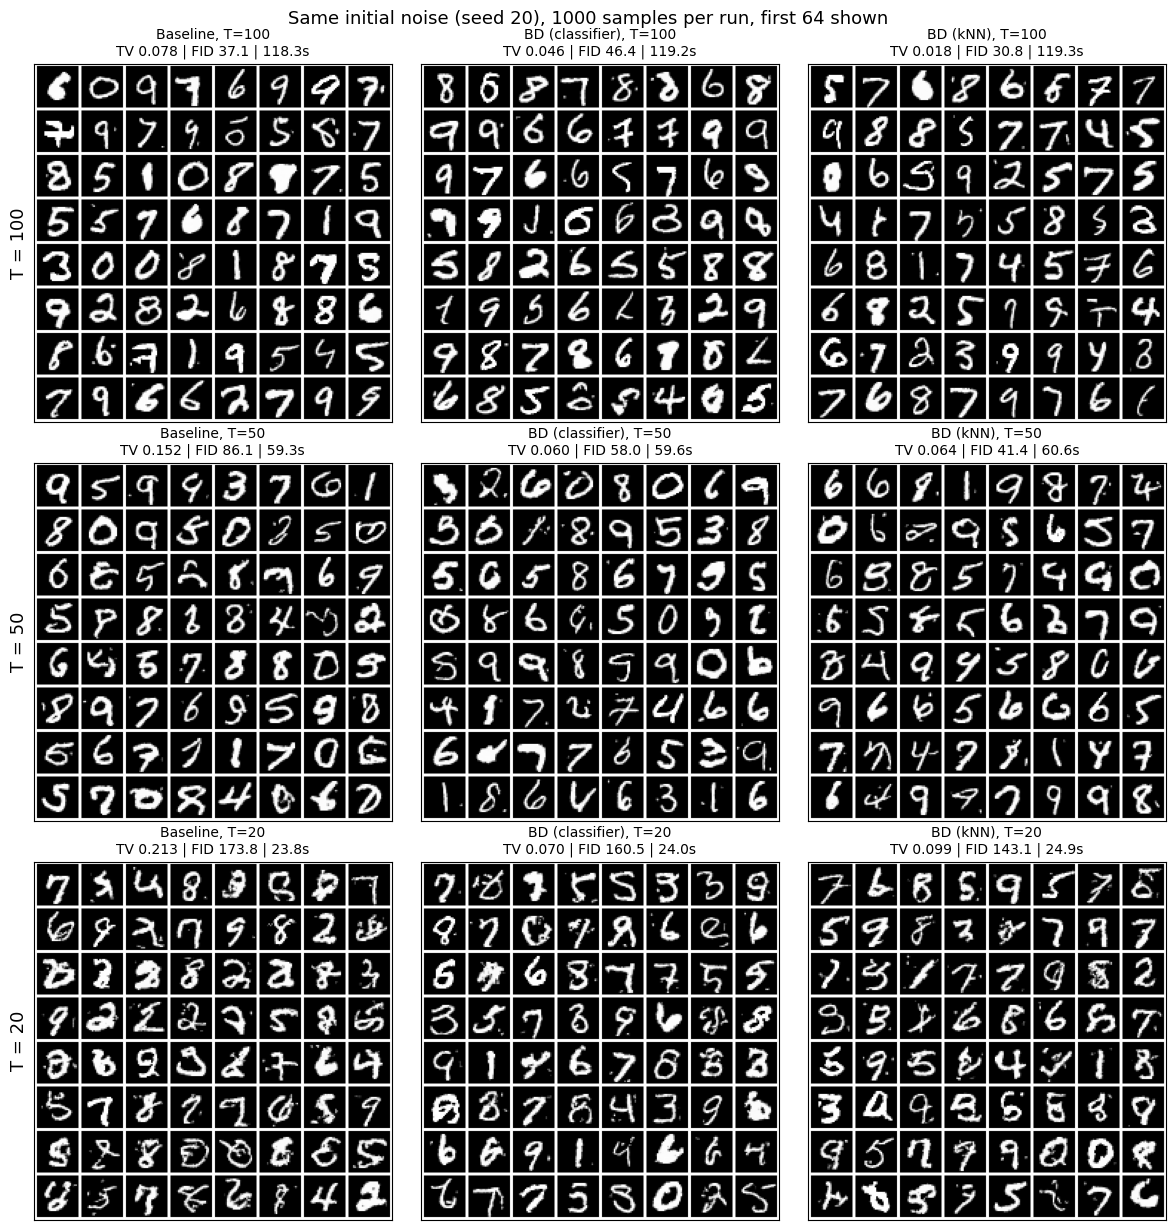

In [7]:
# ===== Sample grid: rows T = 100, 50, 20 | columns baseline, BD classifier, BD kNN | same seed =====
SEED, N = 20, 1000            
ROWS = [100, 50, 20]
COLS = [(None, "Baseline"), ("clf", "BD (classifier)"), ("knn", "BD (kNN)")]

fig, axes = plt.subplots(len(ROWS), len(COLS), figsize=(12, 12.5))
for r, T in enumerate(ROWS):
    for c, (method, name) in enumerate(COLS):
        x, tt, calls = _sample(N, T, method, SEED)          # same seed -> same starting noise in every panel
        m = metrics(x, prior)
        ax = axes[r, c]
        ax.imshow(_grid(x), cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}, T={T}\nTV {m['tv']:.3f} | FID {m['fid']:.1f} | {tt:.1f}s", fontsize=10)
        print(f"T={T:3d} {name:16s} TV {m['tv']:.3f}  FID {m['fid']:7.1f}  time {tt:.1f}s")
    axes[r, 0].set_ylabel(f"T = {T}", fontsize=13)
plt.suptitle(f"Same initial noise (seed {SEED}), {N} samples per run, first 64 shown", fontsize=13)
plt.tight_layout()
os.makedirs("figs", exist_ok=True)
plt.savefig(f"figs/grid_T100_50_20_seed{SEED}.png", dpi=150, bbox_inches="tight")
plt.show()